In [12]:
from lingua import Language, LanguageDetectorBuilder
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

from utils import load_data


In [2]:
#load is found in utils. it loads the raw dataset, removes duplicate rows (only for rows where all columns match)
#also makes a "full_text" row, which are the article titles and texts concatenated
#nulls in the concatenated row are filled with empty strings so they dont coalesce into nulls

df = load_data() 


In [3]:
df.duplicated().sum()

np.int64(0)

In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 63676 entries, 0 to 72132
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   title      63158 non-null  str  
 1   text       63637 non-null  str  
 2   labels     63676 non-null  int64
 3   full_text  63676 non-null  str  
dtypes: int64(1), str(3)
memory usage: 414.4 MB


Labels dont have any nulls. Full_text is an enriched column, not a feature of the raw dataset. Some rows have either titles or text missing.

In [5]:
df.isna().sum()

title        518
text          39
labels         0
full_text      0
dtype: int64

Check if there are any rows where both title and text are null


In [6]:
mask = df["title"].isna() & df["text"].isna()
mask.sum()

np.int64(0)

In [7]:
df.describe(include='all')

,title,text,labels,full_text
count,63158,63637,63676.00000,63676
unique,62338,62705,NaN,63676
top,Factbox: Trump fills top jobs for his administ...,,NaN,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
freq,14,529,NaN,1
mean,NaN,NaN,0.45364,NaN
std,NaN,NaN,0.49785,NaN
min,NaN,NaN,0.00000,NaN
25%,NaN,NaN,0.00000,NaN
50%,NaN,NaN,0.00000,NaN
75%,NaN,NaN,1.00000,NaN


Some articles seem to share titles with different text. Same applies to shared text with different titles. There are no rows where full_text is completely shared (after dropping duplicate rows).

In [8]:
raw_counts = df["labels"].value_counts()

percentages = 100*round(df["labels"].value_counts(normalize=True), 3)

percentage_repr = percentages.astype(str) + "%"

real_fake_stats = pd.concat([raw_counts.rename("count"), percentage_repr.rename("percentages"), ], axis=1)

real_fake_stats.index = real_fake_stats.index.map({0 : "True", 1: "Fake"})

real_fake_stats.index.name = None

real_fake_stats

,count,percentages
True,34790,54.6%
Fake,28886,45.4%


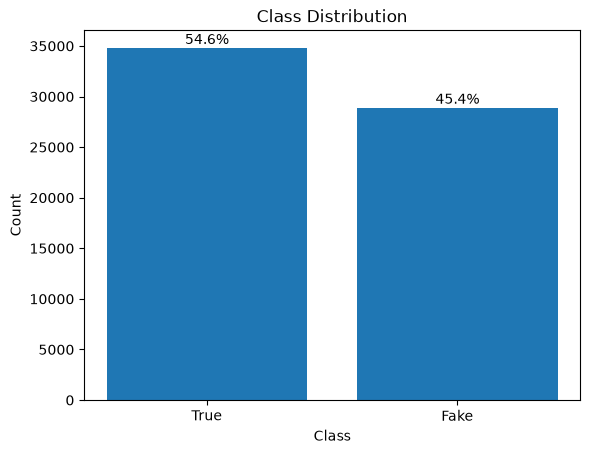

In [9]:
fig, ax = plt.subplots()

bars = ax.bar(real_fake_stats.index , real_fake_stats["count"])

ax.set_title("Class Distribution")

ax.set_xlabel("Class")

ax.set_ylabel("Count")

ax.bar_label(bars, labels=real_fake_stats["percentages"], padding=0.5)

plt.show()

The two classes are ~54.6% and ~45.4%, this is relatively balanced, therefore accuracy metrics wont be misleading later on.

In [10]:
df["article_length"] = df["text"].str.split().str.len()
df["title_length"] = df["title"].str.split().str.len()
df["class"] = df["labels"].map({1: "Fake", 0: "True"}) #class label for visualizations

<Axes: xlabel='class', ylabel='title_length'>

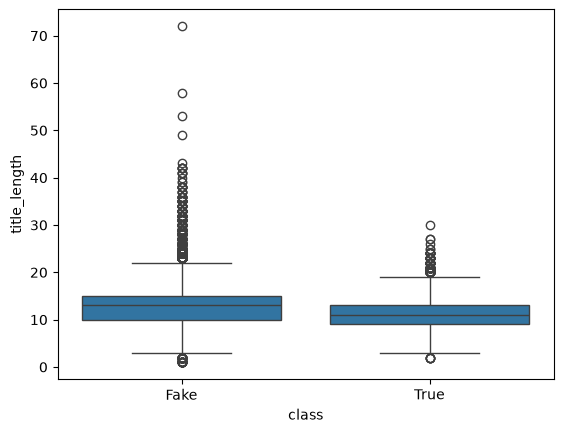

In [13]:
sns.boxplot(data= df, x= "class", y=  "title_length")

<Axes: xlabel='class', ylabel='article_length'>

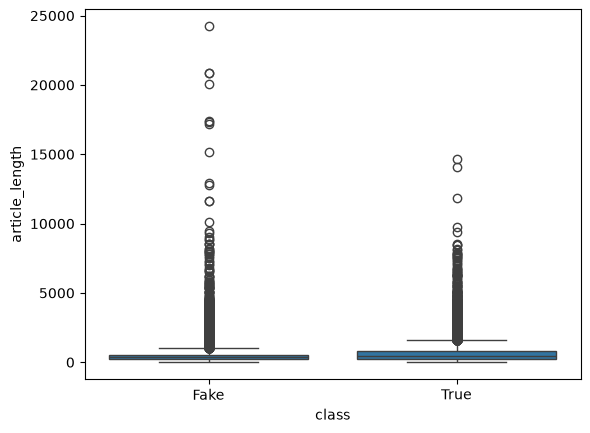

In [14]:
sns.boxplot(data= df, x= "class", y=  "article_length")

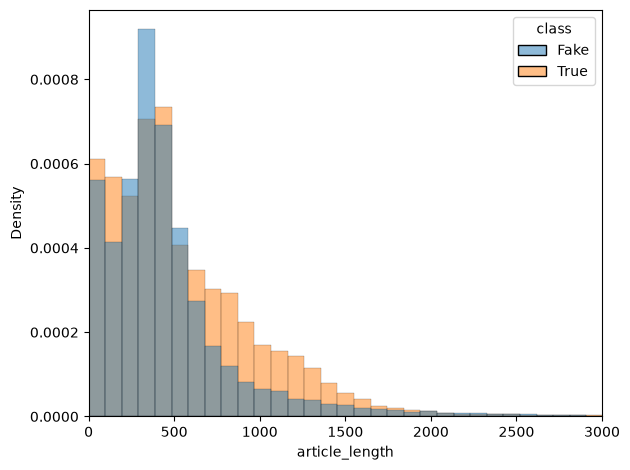

In [15]:
ax = sns.histplot(data = df,
            x = "article_length",
            hue = "class",
            bins = 250,
            kde = False,
            common_norm= True,
            stat = "density")
ax.set_xlim(0,3000)
plt.tight_layout()

There only seem to be some slight differences in article length between the two classes, the models probably wont use this as a shortcut.

Lets investigate word frequencies among the two classes. First, raw word counts, afterwards, their associated class.

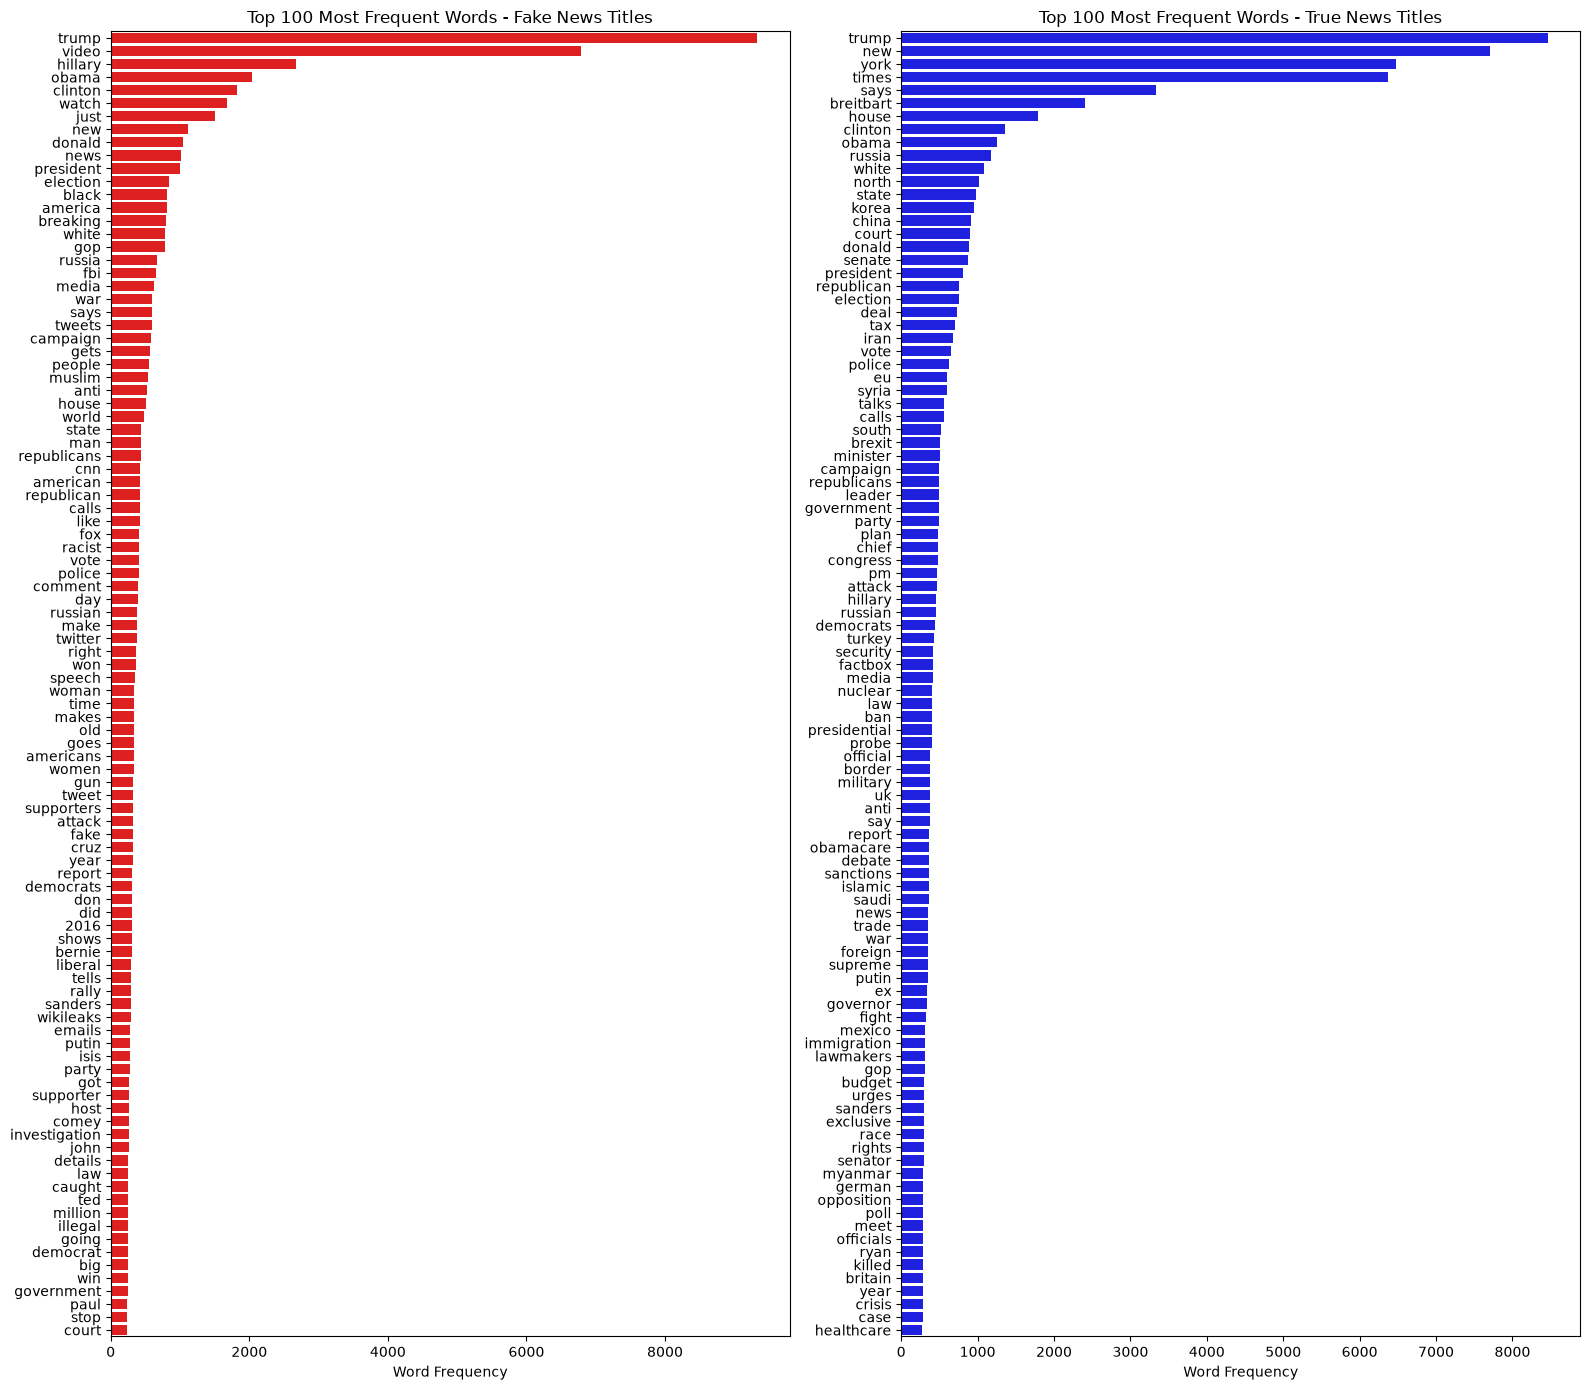

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 14))

for ax, label, color in zip(
    axes,
    ["Fake", "True"],
    ["red", "blue"]
):
    titles = df.loc[df["class"] == label, "title"].fillna("")

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=100,
        min_df=2
    )

    X = vectorizer.fit_transform(titles)

    word_counts = X.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    sns.barplot(
        x=word_counts,
        y=words,
        ax=ax,
        color=color,
        order=words[word_counts.argsort()[::-1]]
    )

    ax.set_title(f"Top 100 Most Frequent Words - {label} News Titles")
    ax.set_xlabel("Word Frequency")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

As expected from a dataset mainly about political news. Lets incestigate their relative frequencies.

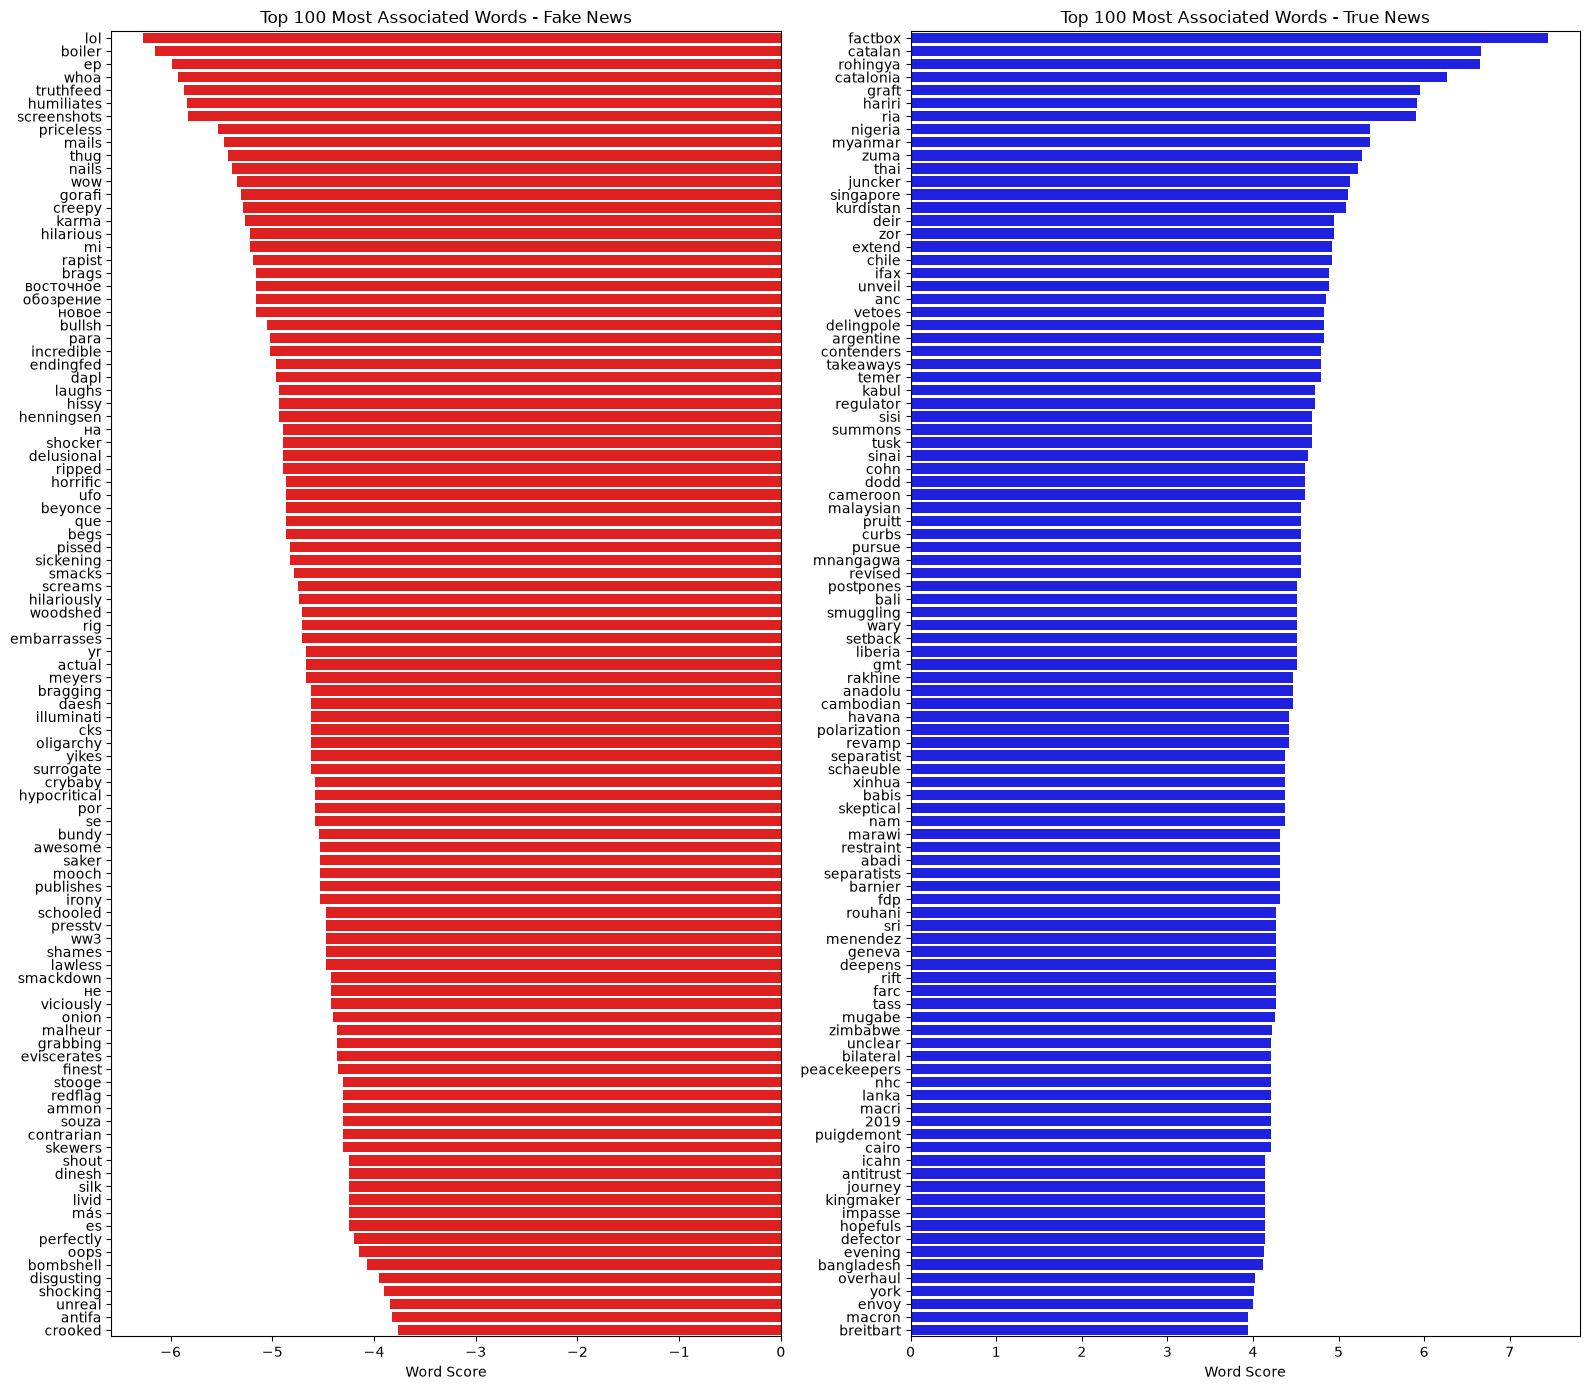

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2
)

X = vectorizer.fit_transform(df["title"].fillna(""))
#vectorizer counts the count of words in each class
words = vectorizer.get_feature_names_out()

fake_counts = np.asarray(
    X[(df["class"] == "Fake").to_numpy()].sum(axis=0)
).ravel()

true_counts = np.asarray(
    X[(df["class"] == "True").to_numpy()].sum(axis=0)
).ravel()

#calculate the frequency of each word separately for the classes

fake_freq = fake_counts / fake_counts.sum()

true_freq = true_counts / true_counts.sum()
alpha =  1e-6
log_scores = np.log((true_freq + alpha)/ (fake_freq + alpha))


fig, axes = plt.subplots(1, 2, figsize=(16, 14))

for ax, label, color in zip(
    axes,
    ["Fake", "True"],
    ["red", "blue"]
):
    class_words = pd.DataFrame({
    "words" : words,
    "log_scores" : log_scores
    }
    )
    ascending = True if label == "Fake" else False

    class_words = class_words.sort_values("log_scores", ascending = ascending).head(100)

    sns.barplot(
        data = class_words,
        x = "log_scores",
        y = "words",
        ax=ax,
        color=color
    )

    ax.set_title(f"Top 100 Most Associated Words - {label} News Titles")
    ax.set_xlabel("Word Score")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

There seem to be russian articles in the dataset. Those will need to be filtered out. First let's 

In [37]:
patterns = [
    "_____",
    "reuters",
    "associated press",
    "read more",
    "click here",
    "click link",
    "(video)",
    "featured image",
    "mcintire",
    "buzzfeed",
    "21wire",
    "getty",
    "abc news",
    "Infowars",
    "Factbox",
    "Trump" #control
]

for pattern in patterns:
    matches = df["title"].str.contains(pattern, regex=False, na=False)
    count = matches.sum()
    fake_count = (matches & df["class"].eq("Fake")).sum()
    rate = fake_count / count if count else 0.0

    print(f"Rate of stopwords in fake news: {pattern}: {rate}")

Rate of stopwords in fake news: _____: 0.0
Rate of stopwords in fake news: reuters: 0.0
Rate of stopwords in fake news: associated press: 0.0
Rate of stopwords in fake news: read more: 0.0
Rate of stopwords in fake news: click here: 0.0
Rate of stopwords in fake news: click link: 0.0
Rate of stopwords in fake news: (video): 1.0
Rate of stopwords in fake news: featured image: 0.0
Rate of stopwords in fake news: mcintire: 0.0
Rate of stopwords in fake news: buzzfeed: 0.0
Rate of stopwords in fake news: 21wire: 0.0
Rate of stopwords in fake news: getty: 0.0
Rate of stopwords in fake news: abc news: 0.0
Rate of stopwords in fake news: Infowars: 1.0
Rate of stopwords in fake news: Factbox: 0.0
Rate of stopwords in fake news: Trump: 0.49587073608617593


the tried stopwords are all in either of the classes, these should be cleaned out during preprocessing to improve generalization


survey the non-english articles

In [38]:
def is_english(text):
    if not isinstance(text, str) or not text.strip():
        return False

    detector = (
    LanguageDetectorBuilder
    .from_all_languages()
    .build())
    language = detector.detect_language_of(text[:500])

    return language == Language.ENGLISH

In [39]:
english_mask = df["full_text"].apply(is_english)

non_english_articles = df[~english_mask]


In [40]:
non_english_articles.to_csv("data/non_english.csv")


In [41]:
non_english_articles.describe(include="all")

,title,text,labels,full_text,article_length,title_length,class
count,520,510,548.000000,548,510.000000,520.000000,548
unique,513,504,NaN,548,NaN,NaN,2
top,Televisión: lo más visto ayer,,NaN,Comment une petite fille russe de 4 ans a appr...,NaN,NaN,Fake
freq,4,4,NaN,1,NaN,NaN,547
mean,NaN,NaN,0.998175,NaN,468.584314,10.171154,NaN
std,NaN,NaN,0.042718,NaN,998.789277,4.339576,NaN
min,NaN,NaN,0.000000,NaN,0.000000,1.000000,NaN
25%,NaN,NaN,1.000000,NaN,167.000000,7.000000,NaN
50%,NaN,NaN,1.000000,NaN,313.500000,10.000000,NaN
75%,NaN,NaN,1.000000,NaN,547.250000,13.000000,NaN
